# Phase 1: nhánh embedding + nhánh luật trên feature đã pool

Code nằm ở `zeroshot/nesy/phase1.py`. Feature đã pool `(N, 256)` lấy từ `neuron_extract/feats/`.

Chạy 3 chế độ cho mỗi split:
- `emb`: chỉ nhánh embedding (cosine với text CLIP). Đây là mức nền.
- `rule`: chỉ nhánh luật (primitive + KG).
- `fused`: kết hợp hai nhánh. **`fused` trừ `emb` là phần đóng góp của KG.**

Số epoch và hệ số γ của GZSL được chọn trên tập validation gồm các lớp pseudo-unseen lấy từ lớp seen. Tập test chỉ được đánh giá một lần.

In [1]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, subprocess, importlib
import numpy as np, pandas as pd, torch, torch.nn.functional as F

DRIVE_DIR = '/content/drive/MyDrive/BaoHuy/zeroshot'
FEAT_DIR  = f'{DRIVE_DIR}/neuron_extract/feats'
OUT_DIR   = f'{DRIVE_DIR}/phase1'
os.makedirs(OUT_DIR, exist_ok=True)

# Repo private thì thêm token GitHub vào Colab > Secrets với tên GH_TOKEN
REPO = '/content/thesis'
if not os.path.exists(REPO):
    try:
        from google.colab import userdata
        tok = userdata.get('GH_TOKEN')
    except Exception:
        tok = None
    url = f'https://{tok}@github.com/NguyenBaoHuy05/thesis.git' if tok else 'https://github.com/NguyenBaoHuy05/thesis.git'
    subprocess.run(['git', 'clone', '-q', url, REPO], check=True)
else:
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
!git -C {REPO} log -1 --format='%h %s'
NESY = f'{REPO}/zeroshot/nesy'
if NESY not in sys.path:
    sys.path.insert(0, NESY)
import phase1
importlib.reload(phase1)
TASKS = list(phase1.UNSEEN)

GPU 0: NVIDIA L4 (UUID: GPU-161775b5-bac0-a046-1429-49ba85fc8036)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1040d6f Add phase 1 NeSy zero-shot model (embedding + rule branch on pooled features)


In [2]:
prims, names, R, imp = phase1.load_kg(f'{REPO}/zeroshot/kg_rules.json', f'{REPO}/zeroshot/primitive.json')
print(f'{len(prims)} primitive, {len(imp)} ràng buộc kéo theo, R: {R.shape}, '
      f'mỗi lớp trung bình {(R > 0).sum(1).mean():.1f} require / {(R < 0).sum(1).mean():.1f} forbid')

# Primitive mà lớp unseen cần nhưng không lớp seen nào require: detector của nó không bao giờ có nhãn dương.
for task in TASKS:
    n_cls = 60 if task.startswith('ntu60') else 120
    unseen = phase1.UNSEEN[task]
    seen = [c for c in range(n_cls) if c not in unseen]
    cov = pd.DataFrame(phase1.coverage(R, seen, unseen, prims))
    cov.insert(1, 'name', [names[c] for c in cov.cls])
    print(f'\n=== {task}: {int((cov.n_uncovered > 0).sum())}/{len(cov)} lớp unseen có primitive chưa được phủ')
    display(cov[cov.n_uncovered > 0])

71 primitive, 13 ràng buộc kéo theo, R: (120, 71), mỗi lớp trung bình 2.9 require / 2.4 forbid

=== ntu60_xsub_seen55_unseen5: 0/5 lớp unseen có primitive chưa được phủ


,cls,name,n_require,n_uncovered,uncovered



=== ntu60_xsub_seen48_unseen12: 8/12 lớp unseen có primitive chưa được phủ


,cls,name,n_require,n_uncovered,uncovered
2,9,clapping,2,1,hands.clapping
5,40,sneeze/cough,2,1,torso.forward_jerk
6,42,falling,2,1,body.falling
7,47,nausea or vomiting condition,3,2,"torso.lean_forward, torso.forward_jerk"
8,51,pushing other person,5,2,"inter.hand_to_other_trunk, inter.other_displaced"
9,56,touch other person's pocket,3,1,inter.hand_to_other_trunk
10,58,walking towards each other,4,2,"body.translating, inter.approaching"
11,59,walking apart from each other,3,2,"body.translating, inter.separating"



=== ntu120_xsub_seen110_unseen10: 1/10 lớp unseen có primitive chưa được phủ


,cls,name,n_require,n_uncovered,uncovered
8,99,butt kicks (kick backward),2,1,leg.heel_to_buttock



=== ntu120_xsub_seen96_unseen24: 4/24 lớp unseen có primitive chưa được phủ


,cls,name,n_require,n_uncovered,uncovered
1,9,clapping,2,1,hands.clapping
8,35,shake head,1,1,head.shake
12,59,walking apart from each other,3,1,inter.separating
13,68,thumb up,3,1,hand.thumb_up


In [ ]:
# Trần của KG: nếu primitive được dự đoán ĐÚNG HOÀN TOÀN thì nhánh luật phân biệt được bao nhiêu lớp unseen?
# Primitive "don't care" của lớp thật không biết đúng/sai, nên thử 2 giả định:
#   dc=0.5: không biết (trung lập);  dc=0: coi như không xảy ra.
# Nếu trần thấp thì lỗi nằm ở KG (luật quá giống nhau), không phải ở mô hình.
importlib.reload(phase1)
ceil_rows = []
for task in TASKS:
    unseen = phase1.UNSEEN[task]
    for dc in (0.5, 0.0):
        acc, rows = phase1.kg_ceiling(R, unseen, dontcare=dc)
        ceil_rows.append(dict(task=task, dontcare=dc, ceiling_zsl=round(acc, 4),
                              n_distinct_rules=len({tuple(R[c]) for c in unseen}), n_unseen=len(unseen)))
        if dc == 0.5:
            amb = [(names[r['cls']], [names[j] for j in r['confused_with']]) for r in rows if r['n_tied_or_above']]
            print(f'{task}: {len(amb)} lớp unseen bị hòa/thua lớp unseen khác (dc=0.5)')
            for a, b in amb[:8]:
                print(f'    {a}  <->  {b}')
display(pd.DataFrame(ceil_rows))

In [3]:
# Text prototype của mỗi lớp, mã hóa bằng CLIP ViT-L/14@336 (cùng text encoder với Neuron).
# Nguồn: tên lớp + 5 file mô tả LLM của Neuron (mỗi lớp 10 câu cho mỗi file).
# Prototype của một nguồn = trung bình các câu (đã chuẩn hóa); prototype cuối = trung bình các nguồn.
TEXT_CACHE = f'{OUT_DIR}/text_proto.npz'
SRC = {'spatial_cg': 'spatial/spatial_cg.json', 'spatial_mg': 'spatial/spatial_mg.json',
       'spatial_fg': 'spatial/spatial_fg.json', 'temporal_fp': 'temporal/temporal_fp.json',
       'temporal_sp': 'temporal/temporal_sp.json'}

if os.path.exists(TEXT_CACHE):
    tp = np.load(TEXT_CACHE)
    src_names, per_src = list(tp['sources']), tp['per_src']
else:
    from transformers import CLIPModel, CLIPTokenizer
    cid = 'openai/clip-vit-large-patch14-336'
    clip = CLIPModel.from_pretrained(cid, torch_dtype=torch.float16).cuda().eval()
    tok = CLIPTokenizer.from_pretrained(cid)

    @torch.no_grad()
    def enc(texts, bs=256):
        out = []
        for i in range(0, len(texts), bs):
            t = tok(texts[i:i + bs], padding=True, truncation=True, max_length=77, return_tensors='pt').to('cuda')
            f = clip.get_text_features(**t)
            if not torch.is_tensor(f):   # một số bản transformers trả về object thay vì tensor
                f = f.text_embeds if getattr(f, 'text_embeds', None) is not None else f.pooler_output
            out.append(F.normalize(f.float(), dim=-1).cpu())
        return torch.cat(out).numpy()

    src_names, protos = ['name'], [enc([f'a person {n}' for n in names])]
    for s, rel in SRC.items():
        d = json.load(open(f'{NESY}/semantics/ntu/{rel}', encoding='utf-8'))
        assert len(d) == 120, (s, len(d))
        keys = list(d)   # thứ tự key = thứ tự lớp 1..120
        diff = [(i, k, names[i]) for i, k in enumerate(keys) if k.lower() not in names[i].lower() and names[i].lower() not in k.lower()]
        print(f'{s}: {len(diff)} tên khác với KG (kiểm tra vài dòng đầu):', diff[:4])
        e = np.stack([enc(d[k]).mean(0) for k in keys])
        protos.append(e / np.linalg.norm(e, axis=1, keepdims=True))
        src_names.append(s)
    per_src = np.stack(protos, 1)               # (120, S, 768)
    np.savez(TEXT_CACHE, per_src=per_src, sources=np.array(src_names))
    del clip

text_proto = per_src.mean(1)
text_proto /= np.linalg.norm(text_proto, axis=1, keepdims=True)
print('sources:', src_names, '| text_proto', text_proto.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.76k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/844 [00:00<?, ?B/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

spatial_cg: 33 tên khác với KG (kiểm tra vài dòng đầu): [(2, 'brush teeth', 'brushing teeth'), (3, 'brush hair', 'brushing hair'), (5, 'pick up', 'pickup'), (7, 'sit down', 'sitting down')]
spatial_mg: 33 tên khác với KG (kiểm tra vài dòng đầu): [(2, 'brush teeth', 'brushing teeth'), (3, 'brush hair', 'brushing hair'), (5, 'pick up', 'pickup'), (7, 'sit down', 'sitting down')]
spatial_fg: 33 tên khác với KG (kiểm tra vài dòng đầu): [(2, 'brush teeth', 'brushing teeth'), (3, 'brush hair', 'brushing hair'), (5, 'pick up', 'pickup'), (7, 'sit down', 'sitting down')]
temporal_fp: 33 tên khác với KG (kiểm tra vài dòng đầu): [(2, 'brush teeth', 'brushing teeth'), (3, 'brush hair', 'brushing hair'), (5, 'pick up', 'pickup'), (7, 'sit down', 'sitting down')]
temporal_sp: 33 tên khác với KG (kiểm tra vài dòng đầu): [(2, 'brush teeth', 'brushing teeth'), (3, 'brush hair', 'brushing hair'), (5, 'pick up', 'pickup'), (7, 'sit down', 'sitting down')]
sources: ['name', 'spatial_cg', 'spatial_mg', 's

In [ ]:
importlib.reload(phase1)
MODES = ['emb', 'rule', 'fused']
SEEDS = [0]                        # thêm 1, 2 khi cấu hình đã ổn
MODEL_KW = dict(hidden=1024, dropout=0.3, beta_init=5.0)
TRAIN_KW = dict(epochs=30, warmup=5, lr=1e-3, wd=1e-4, bs=256, lam_prim=1.0, lam_cons=1.0)
RES_CSV = f'{OUT_DIR}/results.csv'

results, hists, scores = [], {}, {}
for task in TASKS:
    npz = dict(np.load(f'{FEAT_DIR}/{task}.npz'))   # dict(): đọc hết vào RAM, tránh đọc lại từ file zip mỗi lần truy cập
    for mode in MODES:
        for seed in SEEDS:
            res, hist, sc = phase1.run_split(npz, task, text_proto, R, imp, mode=mode, seed=seed,
                                             model_kw=MODEL_KW, train_kw=TRAIN_KW)
            results.append(res)
            hists[(task, mode, seed)] = hist
            scores[(task, mode, seed)] = sc
            pd.DataFrame(results).to_csv(RES_CSV, index=False)

df = pd.DataFrame(results)
show = ['task', 'mode', 'seed', 'epochs', 'val_zsl', 'zsl', 'gzsl_S', 'gzsl_U', 'gzsl_H', 'zsl_s_emb_only', 'zsl_s_rule_only', 'beta']
display((df[[c for c in show if c in df]].round(4)))

In [ ]:
# Ghép sau khi train: z = s_emb (mô hình emb) + beta * s_rule (mô hình rule), train riêng từng nhánh.
# beta chọn trên val ZSL (pseudo-unseen), có cả beta = 0 (= chỉ emb). Test chỉ đọc ra, không dùng để chọn.
# Câu hỏi: có beta > 0 nào làm tốt hơn emb không, trên val và trên test?
importlib.reload(phase1)
ph_rows = []
for task in TASKS:
    for seed in SEEDS:
        chosen, table = phase1.posthoc_fusion(scores[(task, 'emb', seed)], scores[(task, 'rule', seed)])
        t = pd.DataFrame(table)
        emb0 = t[t.beta == 0].iloc[0]
        best_test = t.loc[t.zsl.idxmax()]
        ph_rows.append(dict(task=task, seed=seed, beta_val=chosen['beta'],
                            zsl_emb=emb0.zsl, zsl_posthoc=chosen['zsl'], gain=chosen['zsl'] - emb0.zsl,
                            H_emb=emb0.gzsl_H, H_posthoc=chosen['gzsl_H'],
                            beta_best_on_test=best_test.beta, zsl_best_on_test=best_test.zsl))
        print(f'\n=== {task} seed{seed}')
        display(t.round(4))
ph = pd.DataFrame(ph_rows).round(4)
ph.to_csv(f'{OUT_DIR}/posthoc_fusion.csv', index=False)
display(ph)

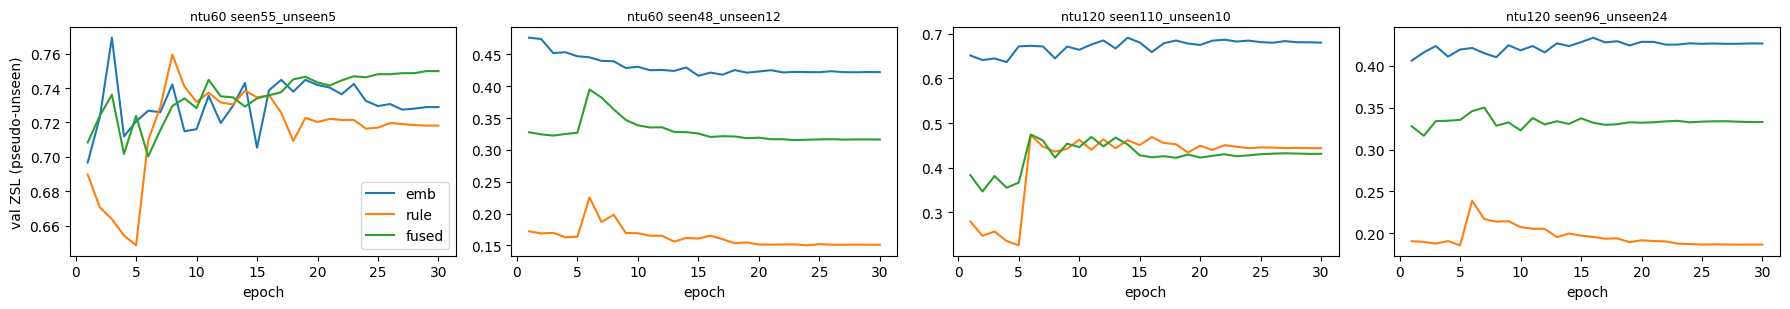

In [5]:
# Đường val ZSL theo epoch: xem có ổn định không và mỗi chế độ hội tụ ở đâu
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(TASKS), figsize=(4.5 * len(TASKS), 3.2))
for ax, task in zip(axes, TASKS):
    for mode in MODES:
        h = hists.get((task, mode, SEEDS[0]))
        if h:
            ax.plot([r['epoch'] for r in h], [r['val_zsl'] for r in h], label=mode)
    ax.set_title(task.replace('_xsub_', ' '), fontsize=9)
    ax.set_xlabel('epoch')
axes[0].set_ylabel('val ZSL (pseudo-unseen)')
axes[0].legend()
plt.tight_layout()
plt.show()

## Đọc kết quả

- **`zsl` của `fused` so với `emb`**: phần chênh này là đóng góp của KG. Đây là con số chính.
- **`rule` đứng một mình**: cho biết bản thân các luật phân biệt được lớp unseen đến đâu. Nếu gần mức ngẫu nhiên (1/5, 1/12, 1/10, 1/24) thì primitive chưa học được. Xem thêm bảng ở cell `kg`: lớp unseen nào có primitive chưa được phủ.
- **`zsl_s_rule_only` / `zsl_s_emb_only`**: từng nhánh của cùng mô hình `fused` khi tách riêng.
- **`val_zsl` so với `zsl`**: nếu chênh lớn thì tập validation (pseudo-unseen) không phản ánh tốt tập test.

Gửi mình bảng ở cell `run` và hình ở cell `curves`.